# 啤酒数据：文件语义与质量

目标：依据 `raw_data/数据说明.txt` 理解 1–8 号文件，做针对性质量检查。

**原则**
- `beer` 暂作为跨表联结键，并在本 Notebook 中验证唯一性与覆盖率。
- `beer_id` 按string读取
- 只输出质量报告和审阅队列，不填补、不删列、不更改原始值。
- 相关系数文件按矩阵检查；品评表按表单布局解析；`8.xlsx` 按 sheet 分别理解。
- 字段名只能提示含义，不能自动证明单位、变换方式或编码口径；这些项目会明确标为待人工确认。

In [4]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.sans-serif"] = ["Hiragino Sans GB", "Arial Unicode MS"]  
plt.rcParams["axes.unicode_minus"] = False 

 


from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert RAW_DIR.exists(), f"未找到原始数据目录: {RAW_DIR}"
print(f"项目目录: {PROJECT_ROOT}")

项目目录: /Users/thomasbuch/Documents/work_for_me/public


## 1. 文件盘点

文件名1
说明：全部 250 个啤酒样品的化学测量数据。

文件名2
说明：所有化学参数之间的 Spearman 相关系数得分。

文件名3
说明：感官分析过程中由经过培训的品评小组使用的品评表。

文件名4
说明：全部 250 个啤酒样品的感官分析结果。

文件名5
说明：所有感官参数之间的 Spearman 相关系数得分。

文件名6
说明：化学参数与感官参数之间的 Spearman 相关系数。

文件名7
说明：针对全部 250 个啤酒样品的感官描述符的论坛评论数据。

文件名8
其他相关数据

In [5]:
inventory = []
for path in sorted(RAW_DIR.iterdir()):
    if path.is_file():
        inventory.append({
            "file": path.name,
            "type": path.suffix.lower().lstrip("."),
            "size_mb": round(path.stat().st_size / 1024**2, 3),
        })
inventory_df = pd.DataFrame(inventory)
display(inventory_df)
inventory_df.to_csv(INTERIM_DIR / "raw_file_manifest.csv", index=False)
print(f"原始文件总计: {inventory_df['size_mb'].sum():.2f} MB")

,file,type,size_mb
0,1.csv,csv,0.668
1,2.csv,csv,0.954
2,3.xlsx,xlsx,0.156
3,4.csv,csv,0.155
4,5.csv,csv,0.046
5,6.csv,csv,0.041
6,7.csv,csv,0.562
7,8.xlsx,xlsx,1.659
8,数据说明.txt,txt,0.001


原始文件总计: 4.24 MB


## 2. 读取与数据地图

In [6]:
csv_tables = {}
for number in [1, 2, 4, 5, 6, 7]:
    path = RAW_DIR / f"{number}.csv"
    csv_tables[number] = pd.read_csv(path, encoding="utf-8-sig", dtype={"beer_id": "string"})

excel_map = {}
for number in [3, 8]:
    path = RAW_DIR / f"{number}.xlsx"
    book = pd.ExcelFile(path)
    excel_map[number] = {sheet: pd.read_excel(path, sheet_name=sheet) for sheet in book.sheet_names}

data_map = []
for number, frame in csv_tables.items():
    data_map.append({"source": f"{number}.csv", "sheet": "-", "rows": len(frame), "columns": frame.shape[1]})
for number, sheets in excel_map.items():
    for sheet, frame in sheets.items():
        data_map.append({"source": f"{number}.xlsx", "sheet": sheet, "rows": len(frame), "columns": frame.shape[1]})
data_map_df = pd.DataFrame(data_map)
display(data_map_df)
data_map_df.to_csv(INTERIM_DIR / "data_map.csv", index=False)

,source,sheet,rows,columns
0,1.csv,-,250,234
1,2.csv,-,231,232
2,4.csv,-,250,53
3,5.csv,-,50,51
4,6.csv,-,44,51
5,7.csv,-,250,189
6,3.xlsx,beer_1,100,33
7,3.xlsx,beer_2,100,33
8,3.xlsx,beer_3,100,33
9,3.xlsx,beer_4,100,33


## 3. 字段质量

### 1.csv：化学测量数据
每行是一个啤酒样品。前三列是项目内样品编号 `beer`、外部商品标识 `beer_id` 和精细类别 `tasting_category_fine`；后续 231 列包含常规理化指标、挥发性化合物和 4 个汇总特征。`beer_id` 必须按文本读取。数值可能已经变换，需结合文件8与化学丰度数据常用处理进行缺失值和异常值的检验和插补。


In [7]:
# 1.csv 标识列确认、指标分类、category 取值、缺失、异常与典型值
chem = pd.read_csv(RAW_DIR / "1.csv", encoding="utf-8-sig", dtype={"beer": "string", "beer_id": "string"})
chem.info()  
display(chem.describe(include="all").T.round(3)) 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Columns: 234 entries, beer to sulfur_sum
dtypes: float64(231), object(1), string(2)
memory usage: 457.2+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
beer,250,250,10,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
beer_id,250,250,5410228202929,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tasting_category_fine,250,22,Blond,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acetaldehyde,250.0,NaN,NaN,NaN,0.578983,0.381415,-1.902829,0.409309,0.61329,0.82209,1.268628
CS2,250.0,NaN,NaN,NaN,-1.898397,0.573002,-2.146292,-2.146292,-2.146292,-2.146292,-0.008552
...,...,...,...,...,...,...,...,...,...,...,...
X2.ethyl.3.methylpyrazine,250.0,NaN,NaN,NaN,0.039496,0.136542,0.000044,0.003722,0.007225,0.024451,1.138484
esters_sum,250.0,NaN,NaN,NaN,0.816187,0.312118,-0.532634,0.680855,0.844305,1.015349,1.468011
aroma_hops_sum,237.0,NaN,NaN,NaN,2.075042,0.647818,0.672328,1.591877,1.989528,2.426674,3.862224
acids_sum,250.0,NaN,NaN,NaN,0.283186,0.373945,-1.204001,0.055835,0.19067,0.43269,1.444068


In [8]:
category = chem["tasting_category_fine"]
category_table = category.value_counts(dropna=False).rename_axis("category").to_frame("samples")
category_table["share"] = (category_table["samples"] / len(chem)).round(3)
display(category_table)


,samples,share
category,,
Blond,31,0.124
Tripel,28,0.112
Strong ale,18,0.072
Hoppy,17,0.068
Stout/Porter,13,0.052
Wheat,12,0.048
Amber,12,0.048
Brown,12,0.048
Lambic,11,0.044


#### 分类A：使用“文件8”Sensory thresholds 表

In [9]:
sheet = excel_map[8]["Sensory thresholds"]
print(f"shape: {sheet.shape[0]} 行 × {sheet.shape[1]} 列;field_name_R 无重复")

overview = pd.DataFrame({
    "role": [
        "python 侧字段名", "R 侧字段名 = 1.csv 实际列名(连接键)", "化合物全名",
        "化合物短名", "是否经仪器校准(yes / yes_gcms)", "原料来源(维度A 词汇来源)",
        "计量单位", "陈化影响(increase / decrease)", "异味感官描述(off-flavor 词汇来源)",
        "感官阈值-均值", "感官阈值-中位数",
    ],
    "non_null": sheet.notna().sum().values,
    "n_unique": sheet.nunique().values,
    "示例": sheet.apply(lambda s: " / ".join(s.dropna().astype(str).head(2))),
}, index=sheet.columns)
display(overview)

matched = sheet["field_name_R"].isin(chem.columns[3:]).sum()
print(f"按 field_name_R 匹配:231/{len(sheet)} 行对应 1.csv 测量列;"
      f"其余 {len(sheet) - matched} 行是未进入 1.csv 的字段的元数据")
print(f"各列覆盖度:origin_paper {sheet['origin_paper'].notna().sum()}/261、unit 77、"
      f"calibrated 68、aging 26、threshold 43、off_flavors 7")


shape: 261 行 × 11 列;field_name_R 无重复


,role,non_null,n_unique,示例
field_name_python,python 侧字段名,261,261,"2,3-hexanedione / acetic acid.g.L."
field_name_R,R 侧字段名 = 1.csv 实际列名(连接键),261,261,X2.3.hexanedione / acetic_acid.g.L.
chemical_name,化合物全名,261,261,"2,3-hexanedione / Acetic acid"
chemical_name_short,化合物短名,261,261,"2,3-hexanedione / Acetic acid"
calibrated,是否经仪器校准(yes / yes_gcms),68,4,yes / yes_gcms
origin_paper,原料来源(维度A 词汇来源),257,7,Internal standard solution / Wild flora
unit,计量单位,77,10,g/L / mg/L
aging,陈化影响(increase / decrease),26,2,increase / increase
off_flavors,异味感官描述(off-flavor 词汇来源),7,7,"pungent, rotten-apples, green apple / buttersc..."
threshold_mean,感官阈值-均值,43,39,0.14025 / 5.0


按 field_name_R 匹配:231/261 行对应 1.csv 测量列;其余 30 行是未进入 1.csv 的字段的元数据
各列覆盖度:origin_paper 257/261、unit 77、calibrated 68、aging 26、threshold 43、off_flavors 7


In [10]:
# 维度 A:来源分类 
measurement = chem.columns[3:]
meta = (excel_map[8]["Sensory thresholds"]
        .drop_duplicates("field_name_R").set_index("field_name_R")
        .reindex(measurement))


unmatched = meta.index[meta["chemical_name"].isna()]
assert len(unmatched) == 0, f"未匹配到元数据的列: {list(unmatched)}"

GROUP_LABELS = {
    "Hops": "酒花 (Hops)",
    "Yeast": "酵母 (Yeast)",
    "Spices": "香料 (Spices)",
    "Malt": "麦芽 (Malt)",
    "Wild flora": "野生菌群 (Wild flora)",
    "Internal standard solution": "内标物 (Internal standard)",
    "Others": "其他 (Others)",
}
by_origin = meta["origin_paper"].map(GROUP_LABELS).fillna("未注明")

GROUP_ORDER = ["酒花 (Hops)", "酵母 (Yeast)", "香料 (Spices)", "麦芽 (Malt)",
               "野生菌群 (Wild flora)", "其他 (Others)", "内标物 (Internal standard)", "未注明"]
GROUP_ORDER = [g for g in GROUP_ORDER if g in set(by_origin)]

origin_table = by_origin.value_counts().reindex(GROUP_ORDER).rename_axis("origin").to_frame("cols")
display(origin_table)
assert int(origin_table["cols"].sum()) == len(measurement), "分组计数与测量列数不一致"

small_groups = origin_table.index[origin_table["cols"] <= 6]
if len(small_groups):
    display(by_origin[by_origin.isin(small_groups)].rename("origin").sort_values().to_frame())


,cols
origin,
酒花 (Hops),77
酵母 (Yeast),78
香料 (Spices),23
麦芽 (Malt),21
野生菌群 (Wild flora),6
其他 (Others),21
内标物 (Internal standard),1
未注明,4


,origin
X3.methyl.2.butenal,内标物 (Internal standard)
esters_sum,未注明
aroma_hops_sum,未注明
acids_sum,未注明
sulfur_sum,未注明
acetic_acid.g.L.,野生菌群 (Wild flora)
lactic_acid.mg.L.,野生菌群 (Wild flora)
isoamyl.lactate,野生菌群 (Wild flora)
X4.ethyl.phenol,野生菌群 (Wild flora)
X4.ethyl.guaiacol,野生菌群 (Wild flora)


#### 分类B：按物质类型

In [11]:
# 维度 B：列名规则
# 由字段名做初步化学类别

# 4个派生汇总特征
summary_features = {
    "esters_sum",
    "aroma_hops_sum",
    "acids_sum",
    "sulfur_sum",
}

# 整体理化指标
bulk_properties = {
    "pH", 
    "ethanol..v.v.", 
    "color.EBC.", 
    "GFS", 
    "protein.g.L.", 
    "iron",
    "betaglucan.mg.L.", 
    "CO2.PSI.", 
    "ammonia.mg.L.", 
    "kcalperc", 
    "bitterness",
}   # GFS=糖, kalcperc=热量, CO2.PSI.=二氧化碳, *.mg.L./*.g.L./*.EBC. 即对应中文项
sulfur_acronyms = {"CS2", "DES", "DMS", "H2S", "MeSH"}

def classify_chemical_class(name):
    n = str(name).lower()
    if name in summary_features:        return "Aggregate feature"
    if name in bulk_properties:         return "Bulk physicochemical property"
    if name in sulfur_acronyms or n.startswith("so2."):
        return "Sulfur compound"                                     # 缩写名先于任何子串规则
    if any(x in n for x in ["acetate","formate","butyrate","propionate","hexanoate",
                            "octanoate","decanoate","isobutyrate","isovalerate",
                            "tiglate","nicotinate","lactate","salicylate","benzoate",
                            "enoate"]) or n.endswith("ate"):
        return "Ester"
    if any(x in n for x in ["terp","humulene","caryophyllene","geraniol","linalool",
                            "citronellol","farnes","nerol","limonene","pinene",
                            "phellandrene","myrcene","bergamotene","aromadendrene",
                            "selinene","muurolene","cadinen","bisabol","sabinene",
                            "germacrene","caryophyllane","manool","ambroxide",
                            "foeniculin"]) or (n.endswith("ene") and name != "styrene"):
        return "Terpenoid"                # 萜类关键词先于泛词尾 -ol/-ene
    if any(x in n for x in ["phenol", "guaiacol"]) or name == "X4VG":
        return "Phenol"
    if n.endswith("ol"):
        return "Alcohol"
    if "acid" in n or "acetic" in n or "lactic" in n:
        return "Organic acid"
    if "aldehyde" in n or n.endswith("al") or "vanillin" in n:
        return "Aldehyde"                 # vanillin 词尾是 -in,需点名
    if "pyrazine" in n:
        return "Pyrazine"
    if "furan" in n:
        return "Furan"
    if n.endswith("one") or "dione" in n or "camphor" in n:
        return "Ketone"                   # camphor 词尾是 -or,需点名
    return "Other / review"

chem_dictionary = pd.DataFrame({"field_name": measurement})
chem_dictionary["chemical_class"] = chem_dictionary["field_name"].apply(classify_chemical_class)

CLASS_ORDER = ["Bulk physicochemical property", "Ester", "Terpenoid", "Alcohol", "Aldehyde",
               "Ketone", "Organic acid", "Sulfur compound", "Furan", "Pyrazine", "Phenol",
               "Aggregate feature", "Internal standard", "Other / review"]
display(chem_dictionary["chemical_class"].value_counts().reindex(CLASS_ORDER).to_frame("cols"))
display(chem_dictionary.loc[chem_dictionary["chemical_class"] == "Other / review", "field_name"].to_frame())
display(chem_dictionary)   # 231 行完整对照


,cols
chemical_class,
Bulk physicochemical property,11.0
Ester,67.0
Terpenoid,55.0
Alcohol,43.0
Aldehyde,19.0
Ketone,10.0
Organic acid,2.0
Sulfur compound,6.0
Furan,4.0


,field_name
35,unfermentables
55,styrene
88,X2.acetylpyrrole
151,geosmin


,field_name,chemical_class
0,acetaldehyde,Aldehyde
1,CS2,Sulfur compound
2,DES,Sulfur compound
3,DMS,Sulfur compound
4,ethyl_2.methyl_butyrate,Ester
...,...,...
226,X2.ethyl.3.methylpyrazine,Pyrazine
227,esters_sum,Aggregate feature
228,aroma_hops_sum,Aggregate feature
229,acids_sum,Aggregate feature


#### 原始文献中与文件 1 处理相关的信息

以下内容直接整理自主文 Methods 的 **Chemical dataset** 和 **Predictive modeling of sensory profiles from chemical data**：

- 250 个商业啤酒样品默认进行两次生物学重复，文章报告每个化学指标的重复均值。
- HS-GC-FID/FPD 用于测定高级醇、乙醛、部分酯、4-vinylguaiacol 和含硫化合物；仪器用含目标挥发物的 5% 乙醇溶液校准。
- HS-SPME-GC-MS 主要测定其他挥发物，尤其是萜类和酯类。色谱峰经背景扣除、保留时间校正和峰面积积分；批次效应以内标 4-fluorobenzaldehyde 归一化。284 个目标化合物中有 167 个的洗脱峰被认为可靠并进入最终分析。
- 乙酸、氨、beta-glucan、iso-alpha acids、色度、糖、甘油、铁、pH、蛋白质和亚硫酸盐由离散光度/酶法测定；乙醇由 NIR 测定；瓶内压力用于计算 CO₂。
- 元数据中 `3-methyl-2-butenal` 的来源被写成 `Internal standard solution`，但补充表 S1 将它列为酵母来源的醛类化合物。本 notebook 的物质类型按补充表归为 `Aldehyde`，来源分类仍保留文件 8 原始标签并将该差异视为元数据待复核项。
- 论文将被判定为对数正态分布的化学指标（Shapiro-Wilk, `p < 0.05`）做对数变换；正文只写了 *log-transformed*，没有说明对数底数。
- 缺失化学测量约占全部数据的 0.1%，论文描述为用各指标均值填补。
- 250 个啤酒按啤酒类型分层，随机拆分为 70% 训练集和 30% 测试集；231 个化学特征按训练集的均值和标准差进行标准化。

注：上述是论文报告的方法。`log10` 与原值的具体对应、底限堆积和单元格缺失情况由本 notebook 的对齐/质量审计单独检查。当前 notebook 不执行数值替换或 NA 填补，也不写出建模副本。

#### 数据异常

In [12]:
thresholds = excel_map[8]["Sensory thresholds"]
column_meta = thresholds.drop_duplicates("field_name_R").set_index("field_name_R")

measurement_columns = measurement          # 沿用维度A cell 定义的列名索引
assert list(measurement_columns) == list(chem.columns[3:])

meta = column_meta.reindex(measurement_columns)
classification = pd.DataFrame({
    "column": measurement_columns,
    "group": by_origin.values,                              # 维度A:来源(纯 origin)
    "chemical_class": (chem_dictionary.set_index("field_name")["chemical_class"]
                       .reindex(measurement_columns).values),  # 维度B:化学类别
    "chemical_name": meta["chemical_name"].values,
    "unit": meta["unit"].values,
    "calibrated": meta["calibrated"].notna().values,
    "aging_effect": meta["aging"].values,
    "off_flavor_note": meta["off_flavors"].values,
})

values = chem[measurement_columns].apply(pd.to_numeric, errors="coerce")
z_scores = (values - values.mean()) / values.std(ddof=0)
classification["missing_n"] = values.isna().sum().values
classification["negative_n"] = (values < 0).sum().values
classification["extreme_n"] = z_scores.abs().gt(3).sum().values
classification["std"] = values.std().values
classification["minimum"] = values.min().values
classification["q1"] = values.quantile(0.25).values
classification["median"] = values.median().values
classification["q3"] = values.quantile(0.75).values
classification["maximum"] = values.max().values


# 1) 列指标分类
display(Markdown("列指标分类"))
group_summary = classification.groupby("group").agg(
    cols=("column", "size"),
    calibrated_cols=("calibrated", "sum"),
    with_unit=("unit", lambda s: s.notna().sum()),
    missing_cells=("missing_n", "sum"),
    negative_cols=("negative_n", lambda s: int((s > 0).sum())),
    off_flavor_cols=("off_flavor_note", lambda s: s.notna().sum()),
    example_columns=("column", lambda s: ", ".join(s.head(3))),
).reindex(GROUP_ORDER)
display(group_summary)

# 4) 缺失
display(Markdown(
    f"**缺失:共 {int(classification['missing_n'].sum())} 个缺失单元格,涉及 "
    f"{int((classification['missing_n'] > 0).sum())} 个测量列,无整列缺失**"
))
display(
    classification.query("missing_n > 0")
    .sort_values("missing_n", ascending=False)
    [["column", "group", "unit", "missing_n", "median", "q3"]]
    .set_index("column").round(3)
)

# 5) 异常
display(Markdown("**异常:负值与 |z|>3 极端值**"))
display(Markdown(
    f"- {int((classification['negative_n'] > 0).sum())}/231 列含负值(共 {int(classification['negative_n'].sum())} 个单元格),"
    f"{int((classification['minimum'] >= 0).sum())} 列恒非负\n"
    f"- |z|>3 共 {int(classification['extreme_n'].sum())} 个单元格,涉及 {int((classification['extreme_n'] > 0).sum())} 列"
))
display(
    classification.nlargest(15, "extreme_n")
    [["column", "group", "extreme_n", "median", "minimum", "maximum"]]
    .set_index("column").round(3)
)



列指标分类

,cols,calibrated_cols,with_unit,missing_cells,negative_cols,off_flavor_cols,example_columns
group,,,,,,,
酒花 (Hops),77,12,15,0,63,0,"bitterness, X3Z.hexenol, alpha.phellandrene"
酵母 (Yeast),78,31,31,37,59,6,"acetaldehyde, CS2, DES"
香料 (Spices),23,1,1,0,21,0,"terpinolene, trans.dihydro.beta.terpineol, cam..."
麦芽 (Malt),21,10,13,20,10,1,"DMS, ammonia.mg.L., color.EBC."
野生菌群 (Wild flora),6,2,4,0,5,0,"acetic_acid.g.L., lactic_acid.mg.L., isoamyl.l..."
其他 (Others),21,11,11,3,14,0,"ethyl_2.methyl_butyrate, ethyl_isovalerate, iron"
内标物 (Internal standard),1,0,0,0,0,0,X3.methyl.2.butenal
未注明,4,0,0,13,3,0,"esters_sum, aroma_hops_sum, acids_sum"


**缺失:共 73 个缺失单元格,涉及 9 个测量列,无整列缺失**

,group,unit,missing_n,median,q3
column,,,,,
amyl.acetate,酵母 (Yeast),mg/L,27,0.002,0.013
aroma_hops_sum,未注明,NaN,13,1.990,2.427
methylpyrazine,麦芽 (Malt),mg/L,12,0.000,0.003
X2.3.butanedione,酵母 (Yeast),mg/L,9,0.285,0.754
X3.methylbutanal,麦芽 (Malt),A.U.,7,0.108,0.229
ethyl.nicotinate,其他 (Others),mg/L,2,0.011,0.044
ethyl.isobutyrate,酵母 (Yeast),mg/L,1,0.043,0.126
furfural,麦芽 (Malt),mg/L,1,0.008,0.028
phenylacetaldehyde,其他 (Others),mg/L,1,0.011,0.029


**异常:负值与 |z|>3 极端值**

- 175/231 列含负值(共 10797 个单元格),56 列恒非负
- |z|>3 共 913 个单元格,涉及 144 列

,group,extreme_n,median,minimum,maximum
column,,,,,
ethyl.octadecanoate,酵母 (Yeast),22,5.056,-1.818,6.670
x.methyl.1.octanol,酵母 (Yeast),21,6.016,-1.818,7.178
X2.undecanol,酒花 (Hops),21,5.270,-1.818,7.193
germacrene.D,酒花 (Hops),20,4.416,-1.818,6.942
neryl.isobutanoate,酒花 (Hops),20,4.416,-1.818,5.587
isoamyl.lactate,野生菌群 (Wild flora),19,5.309,-1.818,7.413
butyl.acetate,酵母 (Yeast),18,4.919,-1.818,8.095
humulene.epoxide.II,酒花 (Hops),18,5.461,-1.818,7.204
alloaromadendrene.epoxide,酒花 (Hops),18,5.863,-1.818,7.595


#### 数据底限与重复最小值
最小值只出现 1 次时，它只是样本最小值，不足以证明是检出限。本节将“列内重复最小值”标记为左删失/底限候选，再结合文件 8 的标定值验证，不把所有最小值自动当作检出限。


,metric,value
0,列数,231
1,最小值重复的列,156
2,底限堆积≥10%的列,79
3,共享最常见底限的列,138


**最常见共享底限:** `-1.81781854`，出现在 138 个有重复最小值的列中。

,floor_value,floor_n,floor_pct,columns_sharing_floor
column,,,,
X6.methyl.5.hepten.2.one,-1.817819,212,0.848,138
limonene,-1.817819,212,0.848,138
CS2,-2.146292,209,0.836,1
cis.dihydro.beta.terpineol,-1.817819,203,0.812,138
ethyl.lactate,-1.817819,195,0.780,138
meta.cymenene,-1.817819,194,0.776,138
beta.humulene,-1.817819,178,0.712,138
valencene,-1.817819,170,0.680,138
X4VG,-2.013157,168,0.672,1


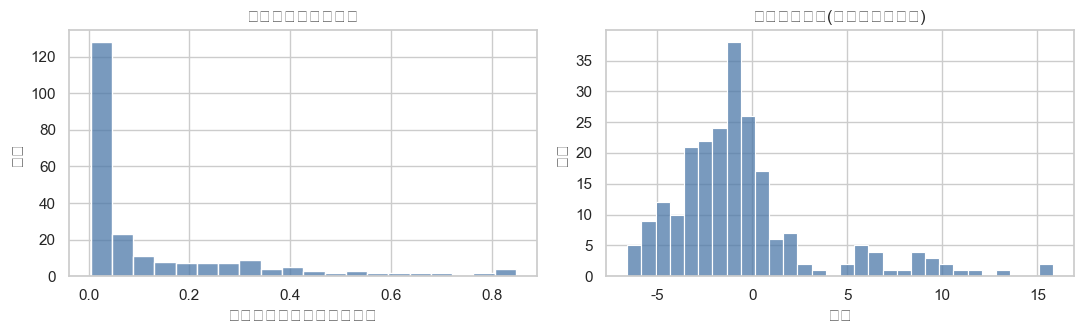

In [13]:
# 列内重复最小值：只做候选标记，不在此处自动替换
floor_records = []
for col in measurement_columns:
    s = values[col].dropna()
    floor_value = s.min()
    floor_n = int(s.eq(floor_value).sum())
    floor_records.append({
        "column": col,
        "nonmissing_n": int(s.size),
        "floor_value": floor_value,
        "floor_n": floor_n,
        "floor_pct": floor_n / s.size,
        "repeated_floor": floor_n >= 2,
        "high_floor_pileup": floor_n / s.size >= 0.10,
    })

floor_audit = pd.DataFrame(floor_records)
floor_audit["floor_value_rounded"] = floor_audit["floor_value"].round(9)
floor_frequency = floor_audit.query("repeated_floor")["floor_value_rounded"].value_counts()
floor_audit["columns_sharing_floor"] = (
    floor_audit["floor_value_rounded"].map(floor_frequency).fillna(0).astype(int)
)

display(pd.DataFrame({
    "metric": ["列数", "最小值重复的列", "底限堆积≥10%的列", "共享最常见底限的列"],
    "value": [
        len(floor_audit),
        int(floor_audit["repeated_floor"].sum()),
        int(floor_audit["high_floor_pileup"].sum()),
        int(floor_frequency.iloc[0]),
    ],
}))
display(Markdown(
    f"**最常见共享底限:** `{floor_frequency.index[0]}`，"
    f"出现在 {int(floor_frequency.iloc[0])} 个有重复最小值的列中。"
))
display(
    floor_audit.query("high_floor_pileup")
    .sort_values(["floor_pct", "floor_n"], ascending=False)
    .head(25)
    [["column", "floor_value", "floor_n", "floor_pct", "columns_sharing_floor"]]
    .set_index("column").round(6)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(floor_audit["floor_pct"], bins=20, ax=axes[0], color="#4C78A8")
axes[0].set(title="各列最小值堆积比例", xlabel="最小值占非缺失样本的比例", ylabel="列数")
sns.histplot(
    values[[c for c in measurement_columns if c not in summary_features]].skew().dropna(),
    bins=30, ax=axes[1], color="#4C78A8",
)
axes[1].set(title="各列偏度分布(排除派生汇总列)", xlabel="偏度", ylabel="列数")
fig.tight_layout()
plt.show()

floor_audit.to_csv(INTERIM_DIR / "file1_floor_audit.csv", index=False)


### 2.csv、5.csv、6.csv：Spearman 相关系数
2.csv 和 5.csv 是分别同一组变量的方阵，应检查范围 [-1,1]、缺失、对称性和对角线是否为 1。6.csv 是化学×感官的矩形交叉相关表。

读取相关系数矩阵,并对照 1.csv/4.csv 原始数据验证是 Pearson 还是 Spearman


In [14]:
norm = lambda s: " ".join(str(s).split())

def fix_mojibake(text):
    try:
        return str(text).encode("latin-1").decode("utf-8")
    except (UnicodeDecodeError, UnicodeEncodeError):
        return text
    
def load_corr_matrix(number):
    frame = csv_tables[number]
    values = frame.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")
    # 标签统一:去首尾空白、压缩内部换行(如 'Overall appreciation\r\n(Trained panel)')
    values.index = [norm(x) for x in frame.iloc[:, 0]]
    values.columns = [norm(x) for x in frame.columns[1:]]
    return values

corr_2 = load_corr_matrix(2)   # 化学×化学 231×231 对称方阵
corr_5 = load_corr_matrix(5)   # 感官×感官 50×50 对称方阵
corr_6 = load_corr_matrix(6)   # 化学×感官 44×50 交叉表

MANUAL_LABEL_FIXES = {
    # "显示名(空白已归一化)": "目标列名",
}

# 官方映射1:化学显示名 → 1.csv 列名(chemical_name 先修 mojibake,261 行唯一)
th_labels = excel_map[8]["Sensory thresholds"].copy()
th_labels["chemical_label"] = th_labels["chemical_name"].map(fix_mojibake).map(norm)
chemical_to_R = th_labels.drop_duplicates("chemical_label").set_index("chemical_label")["field_name_R"].to_dict()

# 官方映射2:感官显示名 → 4.csv 列名(CleanName_PanelFeedback)
sn_labels = excel_map[8]["Sensory names"].query("dataset == 'Trained panel'").copy()
sn_labels["clean"] = sn_labels["CleanName_PanelFeedback"].map(norm)
clean_to_R = sn_labels.drop_duplicates("clean").set_index("clean")["R_name"].to_dict()
clean_to_R["Overall appreciation (Trained panel)"] = "overall"   # 唯一特例:总评分

chemical_to_R.update(MANUAL_LABEL_FIXES)
clean_to_R.update(MANUAL_LABEL_FIXES)

corr_2_R = corr_2.rename(index=chemical_to_R, columns=chemical_to_R)
corr_5_R = corr_5.rename(index=clean_to_R, columns=clean_to_R)
corr_6_R = corr_6.rename(index=chemical_to_R, columns=clean_to_R)

chem_values = csv_tables[1].set_index("beer").iloc[:, 2:].apply(pd.to_numeric, errors="coerce")
sensory_values = csv_tables[4].set_index("beer").drop(columns=["beer_id", "tasting_category_fine"])


def verify_matrix(label, file_matrix, data):
    rows = [c for c in file_matrix.index if c in data.columns]
    cols = [c for c in file_matrix.columns if c in data.columns]
    full = list(dict.fromkeys(rows + cols))
    diffs = {
        method: float(np.nanmax(np.abs(
            file_matrix.loc[rows, cols].values - data[full].corr(method).loc[rows, cols].values)))
        for method in ["spearman", "pearson"]
    }
    method = min(diffs, key=diffs.get)
    return {
        "矩阵": label,
        "核对规模": f"{len(rows)} 行 × {len(cols)} 列",
        "判定方法": method,
        "|文件−Spearman|最大差": f"{diffs['spearman']:.2e}",
        "|文件−Pearson|最大差": f"{diffs['pearson']:.2e}",
        "与重算结果": "✅ 逐元素一致" if diffs[method] < 1e-8 else "❌ 不一致",
    }

method_check = pd.DataFrame([
    verify_matrix("2.csv 化学×化学", corr_2_R, chem_values),
    verify_matrix("5.csv 感官×感官", corr_5_R, sensory_values),
    verify_matrix("6.csv 化学×感官", corr_6_R, chem_values.join(sensory_values, how="inner")),
])
display(method_check)


,矩阵,核对规模,判定方法,|文件−Spearman|最大差,|文件−Pearson|最大差,与重算结果
0,2.csv 化学×化学,231 行 × 231 列,spearman,6.66e-16,1.12e+00,✅ 逐元素一致
1,5.csv 感官×感官,50 行 × 50 列,spearman,5.55e-16,5.41e-01,✅ 逐元素一致
2,6.csv 化学×感官,44 行 × 50 列,spearman,5.55e-16,4.62e-01,✅ 逐元素一致


### 3.xlsx：训练品评小组的非常规评分表
包含 `beer_1`–`beer_12` 十二张格式一致的品评表和一张 `summary`。表单左侧是 Aroma，右侧是 Flavour，品评员在 0–6 强度点位上做标记，Q/AG 列公式将标记转为数值。`summary` 从固定单元格汇总 51 个感官指标。

无数值信息，全为同一模板。

### 4.csv：训练品评小组的 250 样品结果
`A_` 表示 Aroma，`F_` 表示 Flavour；其余列是酸度、苦度、甜度、酒精感、余味、酒体、碳酸感、总体评价以及缺陷/专项风味。

In [15]:
# 4.csv:column check vs 3.xlsx summary + family map
sensory = pd.read_csv(RAW_DIR / "4.csv", encoding="utf-8-sig",
                      dtype={"beer": "string", "beer_id": "string"})
meas = list(sensory.columns[3:])

summary = pd.read_excel(RAW_DIR / "3.xlsx", sheet_name="summary")
panel_metrics = set(summary.columns) - {"Beer"}

# verified transcription differences (4.csv name ↔ summary name)
TRANSCRIPTION = {"X4vg": "4vg",                       # R transcription: leading digit -> X prefix
                 "A_esters_fruity": "A_ester_fruity", # singular/plural inconsistency
                 "F_esters_fruity": "F_ester_fruity"}

assert {TRANSCRIPTION.get(c, c) for c in meas} | {"comments"} == panel_metrics, \
    "unexpected naming difference vs summary"
print(f"column check vs summary: {len(set(meas) & panel_metrics)}/{len(meas)} exact, "
      f"3 transcriptions, summary-only: ['comments']")

# family map: column -> family label (for downstream logic, not display)
SENSORY_FAMILY_MAP = {
    **{c: "aroma" for c in meas if c.startswith("A_")},
    **{c: "flavour" for c in meas if c.startswith("F_")},
    "acidity": "mouthfeel", "bitternes": "mouthfeel", "sweetness": "mouthfeel",
    "alcohol": "mouthfeel", "aftertaste": "mouthfeel", "body": "mouthfeel", "co2": "mouthfeel",
    "X4vg": "fault_special", "diacetyl": "fault_special", "dms": "fault_special",
    "metallic": "fault_special", "stale_hops": "fault_special", "t2n": "fault_special",
    "orange": "fault_special", "coriander": "fault_special", "clove": "fault_special",
    "lactic": "fault_special", "acetic": "fault_special", "barnyard": "fault_special",
    "overall": "overall",
}
assert set(SENSORY_FAMILY_MAP) == set(meas)


column check vs summary: 47/50 exact, 3 transcriptions, summary-only: ['comments']


In [16]:
# 4.csv 数值检查
meas_sensory = list(sensory.columns[3:])
values_sensory = sensory[meas_sensory].apply(pd.to_numeric, errors="coerce")
sensory_class = pd.Series(SENSORY_FAMILY_MAP, name="family")

# 0) 标识列确认
display(pd.DataFrame({
    "check": ["rows", "measurement columns", "beer unique", "beer_id unique (as text)",
              "beer_id scientific notation", "missing cells (all 50 cols)"],
    "result": [len(sensory), len(meas_sensory), sensory["beer"].nunique(),
               sensory["beer_id"].nunique(),
               int(sensory["beer_id"].str.contains(r"[eE][+-]?\d+", na=False).sum()),
               int(values_sensory.isna().sum().sum())],
}))

# 1) 逐列 describe(按维度排序)
desc = values_sensory.describe().T
desc.insert(0, "family", sensory_class.reindex(desc.index))
desc["missing_n"] = values_sensory.isna().sum().astype(int)
display(desc.round(3))

# 2) 分维度层面汇总
display(desc.groupby("family").agg(
    cols=("count", "size"), mean_of_means=("mean", "mean"),
    global_min=("min", "min"), global_max=("max", "max"),
    cols_with_negatives=("min", lambda s: int((s < 0).sum())),
).round(3).reindex(["aroma", "flavour", "mouthfeel", "fault_special", "overall"]))



,check,result
0,rows,250
1,measurement columns,50
2,beer unique,250
3,beer_id unique (as text),96
4,beer_id scientific notation,213
5,missing cells (all 50 cols),0


,family,count,mean,std,min,25%,50%,75%,max,missing_n
A_malt_all,aroma,250.0,0.037,0.717,-1.552,-0.490,-0.118,0.508,2.876,0
A_malt_grain,aroma,250.0,0.018,0.457,-0.971,-0.269,-0.075,0.218,1.759,0
A_malt_bread,aroma,250.0,0.047,0.523,-0.690,-0.300,-0.088,0.229,2.462,0
A_malt_cara,aroma,250.0,0.025,0.628,-0.599,-0.459,-0.184,0.252,2.193,0
A_malt_burn,aroma,250.0,0.019,0.681,-0.447,-0.346,-0.193,0.055,4.104,0
A_hops_all,aroma,250.0,0.001,0.660,-1.362,-0.484,-0.027,0.355,2.488,0
A_hops_citrus,aroma,250.0,-0.012,0.487,-0.580,-0.390,-0.148,0.195,1.818,0
A_hops_tropical,aroma,250.0,0.008,0.611,-0.524,-0.360,-0.168,0.119,3.064,0
A_hops_noble,aroma,250.0,0.001,0.536,-1.027,-0.370,-0.046,0.303,2.123,0
A_hops_woody,aroma,250.0,-0.020,0.370,-0.523,-0.280,-0.112,0.136,1.511,0


,cols,mean_of_means,global_min,global_max,cols_with_negatives
family,,,,,
aroma,15,0.012,-1.700,4.104,15
flavour,15,0.020,-1.650,3.063,15
mouthfeel,7,0.002,-2.151,3.781,7
fault_special,12,-0.018,-0.759,6.172,12
overall,1,-0.008,-1.736,1.346,1


### 7.csv：论坛评论描述符特征
62 个描述符分别以 `aroma_`、`palate_`、`taste_` 出现，共 186 列。存在缺失列。数值包含负数和较大正数，在获得方法说明前称为“描述符特征/得分”，不称为原始词频。

In [17]:
# 7.csv:读取(dtype 注意)、列名分类、aroma 描述符与打分体系匹配
forum = pd.read_csv(RAW_DIR / "7.csv", encoding="utf-8-sig",
                    dtype={"beer": "string", "beer_id": "string"})

# dtype 注意点
non_numeric = [c for c in forum.columns[3:] if not pd.api.types.is_numeric_dtype(forum[c])]
assert not non_numeric, f"非数值特征列: {non_numeric}"
empty_cols = [c for c in forum.columns[3:] if forum[c].notna().sum() == 0]
print(f"整列全空: {empty_cols}")

# 列名分类:62 描述符 × {aroma, palate, taste}
descriptors = sorted({c.split("_", 1)[1] for c in forum.columns[3:]})
assert all(f"{ctx}_{d}" in forum.columns for ctx in ["aroma", "palate", "taste"] for d in descriptors)

# aroma ↔ 打分体系匹配(两跳:描述符 → Ratebeer 官方词汇行 → CleanName_Paper → Trained panel 列)
sensory_names = excel_map[8]["Sensory names"]
ratebeer_aroma = sensory_names.query("dataset == 'Ratebeer' and R_name.str.startswith('aroma_')")
panel = sensory_names[sensory_names["dataset"] == "Trained panel"]

aroma_cols = [c for c in forum.columns[3:] if c.startswith("aroma_")]
match_rows = []
for col in aroma_cols:
    descriptor = col.removeprefix("aroma_")
    official = ratebeer_aroma.loc[ratebeer_aroma["R_name"] == col, "CleanName_Paper"].dropna()
    panel_hits = sorted(panel.loc[panel["CleanName_Paper"].isin(official), "R_name"].tolist())
    match_rows.append({
        "aroma_column": col,
        "official_ratebeer": bool(len(official)),
        "panel_columns": ", ".join(panel_hits) if panel_hits else "",
    })
aroma_match = pd.DataFrame(match_rows)
matched_n = int((aroma_match["panel_columns"] != "").sum())
print(f"通过官方 Ratebeer 词汇桥匹配到打分体系: {matched_n}/{len(aroma_cols)}")
display(aroma_match)


整列全空: ['palate_acetaldehyde', 'palate_acetate', 'palate_dentist']
通过官方 Ratebeer 词汇桥匹配到打分体系: 18/62


,aroma_column,official_ratebeer,panel_columns
0,aroma_acetaldehyde,False,
1,aroma_acetate,False,
2,aroma_acetic,False,
3,aroma_acidic,False,
4,aroma_aftertaste,False,
5,aroma_alcohol,False,
6,aroma_anise,False,
7,aroma_apple,False,
8,aroma_banana,True,"A_esters_isoaa, F_esters_isoaa"
9,aroma_barnyard,False,


dtype 检查:186 特征列全为数值;
结构: 62 个描述符 × 3 上下文 = 186 列,三组描述符集合完全一致

In [18]:
# 7.csv 数值分析第一步:基本统计量与分布形态
values_forum = forum.iloc[:, 3:]
informative = values_forum.loc[:, values_forum.notna().any()]   # 183 列;3 个全空列已在上一步登记

stats_forum = pd.DataFrame({
    "context": [c.split("_", 1)[0] for c in informative.columns],
    "min": informative.min(), "max": informative.max(),
    "mean": informative.mean(), "std": informative.std(),
    "skew": informative.skew(), "kurtosis": informative.kurt(),
    "negative_share": (informative < 0).mean(),
}).round(3)

display(stats_forum.groupby("context").agg(
    cols=("mean", "size"), mean_of_means=("mean", "mean"), mean_of_std=("std", "mean"),
    global_min=("min", "min"), global_max=("max", "max"),
    median_neg_share=("negative_share", "median"), mean_skew=("skew", "mean"),
).reindex(["aroma", "palate", "taste"]).round(3))


,cols,mean_of_means,mean_of_std,global_min,global_max,median_neg_share,mean_skew
context,,,,,,,
aroma,62,-0.001,0.996,-2.137,15.812,0.720,4.694
palate,59,-0.002,0.971,-4.936,15.812,0.840,6.158
taste,62,-0.000,0.999,-2.275,15.392,0.694,3.984


大多数描述符近似零均值、单位方差，但部分低频描述符方差明显较低；
183 列全部含负值,负值占比中位数约 0.76,零值几乎为 0 → 稠密连续得分,不是词频/计数；
其变换可能受到稀疏性、截断或原始出现次数影响


### 8.xlsx：辅助元数据、模型结果与价格
| Sheet                         | 数据内容                                                                    |
| ----------------------------- | ----------------------------------------------------------------------- |
| `Sensory thresholds`          | 化学指标的名称、来源、单位、校准状态、感官阈值等元数据                                             |
| `Sensory names`               | 感官指标的名称映射，例如论文名称、R 名称、Python 名称、Aroma/Taste/Palate 分类                   |
| `GBM importance MDI`          | Gradient Boosting Model 的 MDI feature importance（基于树分裂 impurity 的特征重要性） |
| `GBM SHAP Values`             | GBM 模型的 SHAP values（每个样品和化学指标对预测结果的贡献）                                  |
| `Calibrated chemical dataset` | 250 款啤酒的部分校准化学数据，可与表格 1 对照检查单位和变换                                       |
| `Beer Prices`                 | 啤酒价格、酒精度、风格等市场数据                                                        |
| `Sheet2`                      | 空表，没有实际数据                                                               |

In [19]:
# 8.xlsx 全局检查
book = pd.ExcelFile(RAW_DIR / "8.xlsx")
global_report = []
for name in book.sheet_names:
    df = pd.read_excel(RAW_DIR / "8.xlsx", sheet_name=name)
    global_report.append({
        "sheet": name, "rows": df.shape[0], "cols": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_col_names": int(df.columns.duplicated().sum()),
        "all_empty": bool(df.dropna(how="all").empty and df.dropna(axis=1, how="all").empty),
    })
sheet_report = pd.DataFrame(global_report)
display(sheet_report)
assert sheet_report.loc[sheet_report.sheet == "Sheet2", "all_empty"].iloc[0], "Sheet2 应为空"
print("Sheet2: empty worksheet, no analytical content")

,sheet,rows,cols,duplicate_rows,duplicate_col_names,all_empty
0,Sensory thresholds,261,11,0,0,False
1,Sensory names,101,8,0,0,False
2,GBM importance MDI,231,2,0,0,False
3,GBM SHAP Values,500,236,0,0,False
4,Calibrated chemical dataset,250,73,0,0,False
5,Beer Prices,250,11,0,0,False
6,Sheet2,0,0,0,0,True


Sheet2: empty worksheet, no analytical content


#### sensory thresholds

In [20]:
# thresholds:唯一性、unit 词表、calibrated 规范化(派生列)、threshold 数值检查
thresholds = excel_map[8]["Sensory thresholds"]
assert thresholds["field_name_python"].is_unique and thresholds["field_name_R"].is_unique

display(thresholds["unit"].value_counts(dropna=False).rename_axis("unit").to_frame("rows"))
# 10 种:mg/L ug/L g/L A.U. EBC IBU PSI pH kcal% v/v

th_check = thresholds.copy()
th_check["calibrated_std"] = th_check["calibrated"].astype("string").str.replace(r"\s+", "", regex=True)
print("calibrated 规范化后:", th_check["calibrated_std"].value_counts(dropna=False).to_dict())
# {NaN: 193, yes_gcms: 45, yes: 35} —— 'yes_gcms,yes' 与 'yes_gcms, yes' 只是空格差异,归并为 yes_gcms

for col in ["threshold_mean", "threshold_median"]:
    v = pd.to_numeric(th_check[col], errors="coerce")
    assert v.notna().equals(th_check[col].notna()), f"{col} 存在非数值"
    print(f"{col}: 非空 {int(v.notna().sum())}, min={v.min():.4f}, ≤0 共 {int((v <= 0).sum())} 个")
# threshold 无负值/零值;缺失(218 行)表示"无阈值",保持 NaN,不填 0


,rows
unit,
NaN,184
mg/L,52
A.U.,10
ug/L,5
g/L,4
IBU,1
v/v,1
kcal%,1
PSI,1


calibrated 规范化后: {<NA>: 193, 'yes_gcms': 33, 'yes': 23, 'yes_gcms,yes': 12}
threshold_mean: 非空 43, min=0.0245, ≤0 共 0 个
threshold_median: 非空 43, min=0.0045, ≤0 共 0 个


#### sensory name

In [21]:
# sensory names:唯一性按 dataset 口径;一对多映射是设计而非错误
sensory_names = excel_map[8]["Sensory names"]
for ds, group in sensory_names.groupby("dataset"):
    print(f"{ds}: {len(group)} 行,R_name dataset 内唯一 = {group['R_name'].is_unique}")
print("全表 R_name 重复:", sensory_names.loc[sensory_names['R_name'].duplicated(keep=False), 'R_name'].unique().tolist())  # ['aroma_citrus']

display(sensory_names["Category"].value_counts(dropna=False).rename_axis("category").to_frame("rows"))
display(sensory_names.groupby("dataset")["DataType"].value_counts(dropna=False).to_frame("rows"))
print("一个 CleanName_Paper 最多对应 4 个 R_name(panel 的 A_/F_ + Ratebeer 的 aroma/taste),按设计保留全部别名")


Ratebeer: 51 行,R_name dataset 内唯一 = False
Trained panel: 50 行,R_name dataset 内唯一 = True
全表 R_name 重复: ['aroma_citrus']


,rows
category,
Yeast,24
Others,23
Hops,20
Malt,20
NaN,10
Wild flora,4


rows
dataset       DataType         
Ratebeer      NaN            51
Trained panel numeric        26
              categorical    24

一个 CleanName_Paper 最多对应 4 个 R_name(panel 的 A_/F_ + Ratebeer 的 aroma/taste),按设计保留全部别名


#### Calibrated chemical dataset

In [22]:
# calibrated:结构、键、类型、单位关联（此处只查结构；变换对照在 notebook 末尾完成）
calibrated = excel_map[8]["Calibrated chemical dataset"]
assert len(calibrated) == 250 and calibrated["beer"].is_unique
assert set(calibrated["beer"]) == set(chem["beer"].astype(int)), "beer 集合与表1不一致"
assert calibrated["beer_id"].astype(str).str.contains(r"e\+", case=False, regex=True).sum() == 0
assert all(pd.api.types.is_numeric_dtype(calibrated[c]) for c in calibrated.columns[3:])
assert not calibrated.columns[3:].duplicated().any()

units_via_th = thresholds.set_index("field_name_R")["unit"].reindex(calibrated.columns[3:])
print(f"70 列中 {int(units_via_th.notna().sum())} 列在 thresholds 有单位;缺单位: {units_via_th[units_via_th.isna()].index.tolist()}")
# beer_id 为 13 位 EAN 整数,当前读法无精度损失;导出 CSV 时必须保持 int/string,禁止转 float
# 变换对照结论见维度 C:37 log10 / 33 原值 / 0 ln / 157 无标定对照 / 4 派生


70 列中 68 列在 thresholds 有单位;缺单位: ['unfermentables', 'ethyl.pentanoate']


#### GBM importance MDI

In [23]:
# MDI:第 0 行是异常表头[空, 0];真实结构 = 231 行 × (importance, feature)
mdi = pd.read_excel(RAW_DIR / "8.xlsx", sheet_name="GBM importance MDI", header=None, skiprows=1)
mdi.columns = ["importance", "feature"]

assert set(mdi["feature"]) == set(measurement_columns), "MDI 特征名与 1.csv 不一致"
assert list(mdi["feature"]) == list(measurement_columns), "MDI 特征顺序与 1.csv 列序不一致"   # 实测顺序也完全一致
assert len(mdi) == 231 and mdi["importance"].notna().all()

print(f"importance: sum={mdi['importance'].sum():.6f}(归一化), min={mdi['importance'].min():.6f}, 负值 {int((mdi['importance'] < 0).sum())} 个")
display(mdi.nlargest(10, "importance"))
# 定位:模型输出,不是测量;不当因果强度,不并回化学特征表


importance: sum=1.000000(归一化), min=0.000054, 负值 0 个


,importance,feature
5,0.222213,ethyl_acetate
33,0.067043,ethanol..v.v.
9,0.054115,ethyl_octanoate
125,0.046184,ethyl.phenylacetate
26,0.044161,lactic_acid.mg.L.
30,0.023996,protein.g.L.
16,0.023562,MeSH
55,0.022832,styrene
229,0.021912,acids_sum
126,0.018954,isopentyl.hexanoate


#### GBM SHAP Values

In [24]:
# SHAP:逐样品模型解释,双行长结构
shap_values = excel_map[8]["GBM SHAP Values"]
print("data 取值:", shap_values["data"].value_counts().to_dict())          # {'SHAP': 250, 'concentration': 250}
print("每个 beer 恰好 2 行:", bool(shap_values.groupby('beer').size().eq(2).all()), "| beer 覆盖:", shap_values['beer'].nunique())
feature_cols = [c for c in shap_values.columns if c not in {"beer", "data"}]
unmatched = [c for c in feature_cols if c not in chem.columns]
print(f"特征列 {len(feature_cols)} = 231 化学列 + {unmatched}")

# SHAP:标识/标签 4 列 + 231 化学特征列 + base_prediction
id_cols = ["data", "beer", "beer_id", "tasting_category_fine"]
feature_cols = [c for c in shap_values.columns if c not in id_cols + ["base_prediction"]]

assert set(feature_cols) == set(measurement_columns), "SHAP 特征名与 1.csv 不一致"
assert feature_cols == list(measurement_columns), "SHAP 特征顺序与 1.csv 列序不一致"
per_beer_ok = shap_values.groupby("beer")["data"].apply(lambda s: sorted(s) == ["SHAP", "concentration"])
assert per_beer_ok.all(), "存在 beer 的 SHAP/concentration 行数不为 1+1"

shap_rows = shap_values.query("data == 'SHAP'")
conc_rows = shap_values.query("data == 'concentration'")
missing_report = pd.DataFrame({
    "shap_rows_missing": shap_rows[feature_cols].isna().sum(),
    "concentration_rows_missing": conc_rows[feature_cols].isna().sum(),
})
display(missing_report.loc[missing_report.sum(axis=1) > 0])
print(f"SHAP 行缺失: {int(missing_report['shap_rows_missing'].sum())} | "
      f"concentration 行缺失: {int(missing_report['concentration_rows_missing'].sum())} 个单元格")

print(f"base_prediction 恒为 {shap_rows['base_prediction'].iloc[0]:.4f}(250 个 beer 同值,即模型基准项)")
additive = shap_rows["base_prediction"] + shap_rows[feature_cols].sum(axis=1)
print(f"base + ΣSHAP(即隐含预测): [{additive.min():.4f}, {additive.max():.4f}], mean={additive.mean():.4f}")


data 取值: {'SHAP': 250, 'concentration': 250}
每个 beer 恰好 2 行: True | beer 覆盖: 250
特征列 234 = 231 化学列 + ['base_prediction']


,shap_rows_missing,concentration_rows_missing
X2.3.butanedione,0,9
X3.methylbutanal,0,7
ethyl.isobutyrate,0,1
methylpyrazine,0,12
furfural,0,1
amyl.acetate,0,27
phenylacetaldehyde,0,1
ethyl.nicotinate,0,2
aroma_hops_sum,0,13


SHAP 行缺失: 0 | concentration 行缺失: 73 个单元格
base_prediction 恒为 -0.3263(250 个 beer 同值,即模型基准项)
base + ΣSHAP(即隐含预测): [-2.9129, 1.3719], mean=-0.3290


#### Beer Prices

In [25]:
# prices:外部变量,不进化学特征矩阵
prices = excel_map[8]["Beer Prices"]
assert prices["beer"].is_unique and set(prices["beer"]) == set(chem["beer"].astype(int))
price_cols = [c for c in prices.columns if c.startswith("Price_")]
print("价格列全数值:", all(pd.api.types.is_numeric_dtype(prices[c]) for c in price_cols))
print("价格 ≤0 的单元格:", int((prices[price_cols] <= 0).sum().sum()))
print(f"ABV 范围 [{prices['ABV'].min()}, {prices['ABV'].max()}];ABV=0 的样品: {prices.loc[prices['ABV']==0,'beer'].tolist()}(对应 low/no alcohol,合理,记录备查)")
display(prices[price_cols].isna().sum().rename("missing").sort_values(ascending=False).to_frame())
print("注意:tasting_category 是粗类别(blond/brut/...),与表1的 tasting_category_fine 不是同一粒度")
# 缺失即"该渠道无售/未采集",含义与化学缺失不同,不填补;货币未统一标注,跨国比较前需确认


价格列全数值: True
价格 ≤0 的单元格: 0
ABV 范围 [0.0, 12.0];ABV=0 的样品: [10, 223](对应 low/no alcohol,合理,记录备查)


,missing
Price_BeerHawk_UK,204
Price_Colruyt_Belgium,170
Price_TotalWine_USA,164
Price_Delhaize_Belgium,159
Price_TheBelgianBeerShop_global,156
Price_BeerOfBelgium_global,109
Price_TheBelgianShop_global,43


注意:tasting_category 是粗类别(blond/brut/...),与表1的 tasting_category_fine 不是同一粒度


## 4. 主键、样本覆盖与类别一致性

In [26]:
main_tables = {number: csv_tables[number] for number in [1, 4, 7]}
key_checks = []
for number, frame in main_tables.items():
    key_checks.append({
        "source": f"{number}.csv",
        "rows": len(frame),
        "beer_unique": frame["beer"].nunique(dropna=True),
        "beer_duplicates": int(frame["beer"].duplicated().sum()),
        "beer_id_unique_as_text": frame["beer_id"].nunique(dropna=True),
        "beer_id_scientific_notation_n": int(frame["beer_id"].str.contains(r"[eE][+-]?\d+", na=False).sum()),
        "category_missing_n": int(frame["tasting_category_fine"].isna().sum()),
    })
key_checks_df = pd.DataFrame(key_checks)
display(key_checks_df)

pair_checks = []
for left, right in [(1, 4), (1, 7), (4, 7)]:
    merged = main_tables[left][["beer", "tasting_category_fine"]].merge(
        main_tables[right][["beer", "tasting_category_fine"]],
        on="beer", how="outer", suffixes=("_left", "_right"), indicator=True, validate="one_to_one"
    )
    pair_checks.append({
        "pair": f"{left}.csv vs {right}.csv",
        "matched_beer_n": int((merged["_merge"] == "both").sum()),
        "left_only_n": int((merged["_merge"] == "left_only").sum()),
        "right_only_n": int((merged["_merge"] == "right_only").sum()),
        "category_mismatch_n": int((merged["tasting_category_fine_left"] != merged["tasting_category_fine_right"]).sum()),
    })
pair_checks_df = pd.DataFrame(pair_checks)
display(pair_checks_df)
pd.concat([key_checks_df.assign(check_type="within_table"), pair_checks_df.assign(check_type="between_tables")], axis=0).to_csv(
    INTERIM_DIR / "key_checks.csv", index=False
)

,source,rows,beer_unique,beer_duplicates,beer_id_unique_as_text,beer_id_scientific_notation_n,category_missing_n
0,1.csv,250,250,0,250,0,0
1,4.csv,250,250,0,96,213,0
2,7.csv,250,250,0,96,213,0


,pair,matched_beer_n,left_only_n,right_only_n,category_mismatch_n
0,1.csv vs 4.csv,250,0,0,0
1,1.csv vs 7.csv,250,0,0,0
2,4.csv vs 7.csv,250,0,0,0


## 5. 缺失值与类别分布

,source,column,missing_n,missing_pct
9,7.csv,palate_acetaldehyde,250,1.000
10,7.csv,palate_acetate,250,1.000
11,7.csv,palate_dentist,250,1.000
5,1.csv,amyl.acetate,27,0.108
8,1.csv,aroma_hops_sum,13,0.052
3,1.csv,methylpyrazine,12,0.048
0,1.csv,X2.3.butanedione,9,0.036
1,1.csv,X3.methylbutanal,7,0.028
7,1.csv,ethyl.nicotinate,2,0.008
2,1.csv,ethyl.isobutyrate,1,0.004


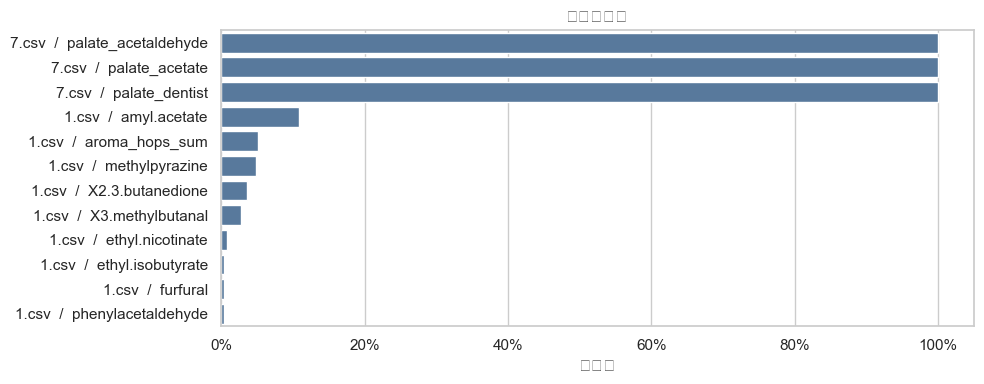

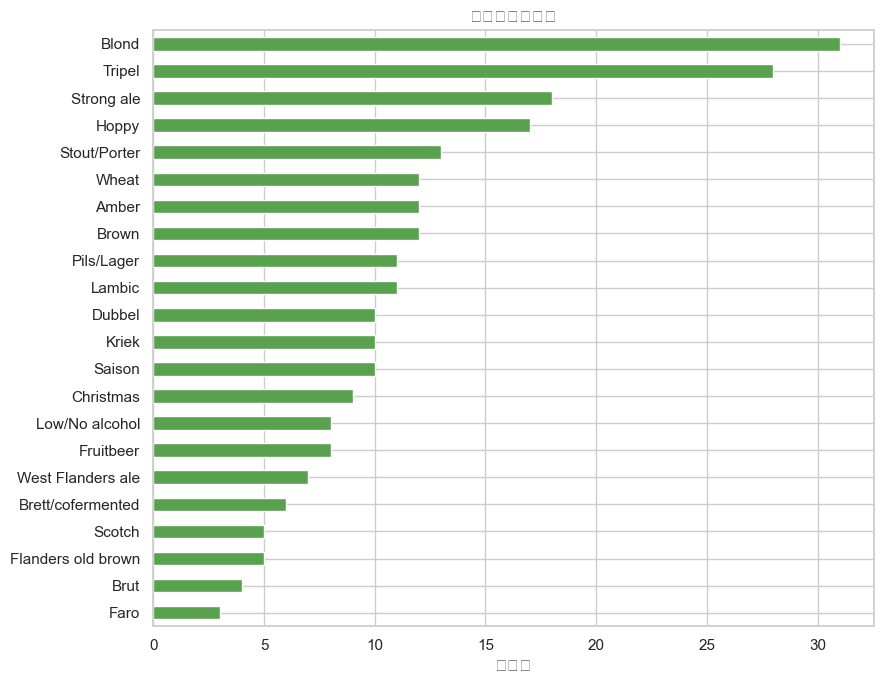

In [27]:
missing_rows = []
for number, frame in main_tables.items():
    for column, count in frame.isna().sum().items():
        if count > 0:
            missing_rows.append({"source": f"{number}.csv", "column": column, "missing_n": int(count), "missing_pct": count / len(frame)})
missing_df = pd.DataFrame(missing_rows).sort_values(["missing_pct", "source"], ascending=[False, True])
display(missing_df)

if not missing_df.empty:
    plot_df = missing_df.copy()
    plot_df["label"] = plot_df["source"] + "  /  " + plot_df["column"]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.33 * len(plot_df))))
    sns.barplot(data=plot_df, x="missing_pct", y="label", color="#4C78A8", ax=ax)
    ax.set(title="主表缺失率", xlabel="缺失率", ylabel="")
    ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "missingness.png", dpi=160, bbox_inches="tight")
    plt.show()

category_counts = csv_tables[1]["tasting_category_fine"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
category_counts.plot.barh(ax=ax, color="#59A14F")
ax.set(title="啤酒类别样本数", xlabel="样本数", ylabel="")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "category_counts.png", dpi=160, bbox_inches="tight")
plt.show()

In [28]:
# 8.xlsx：按 sheet 的真实角色与关键结构检查
file8_roles = {
 'Sensory thresholds': '化学字段、来源、单位、校准和感觉阈值元数据',
 'Sensory names': 'Trained panel 与 Ratebeer 感官字段的命名/分类映射',
 'GBM importance MDI': '231 个化学特征的 GBM mean decrease impurity 重要性',
 'GBM SHAP Values': '每个 beer 两行：SHAP 贡献与 concentration/模型特征值',
 'Calibrated chemical dataset': '250 个啤酒×70 个经校准/筛选的化学指标子集',
 'Beer Prices': '250 个啤酒的 ABV 和多零售渠道价格，货币/容量/日期待确认',
 'Sheet2': '空工作表'
}
file8_summary = []
for name, frame in excel_map[8].items():
    file8_summary.append({'sheet': name, 'role': file8_roles.get(name,'待确认'), 'rows': len(frame), 'columns': frame.shape[1], 'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum())})
file8_summary = pd.DataFrame(file8_summary)
display(file8_summary)
shap = excel_map[8]['GBM SHAP Values']
calibrated = excel_map[8]['Calibrated chemical dataset']
prices = excel_map[8]['Beer Prices']
file8_checks = pd.DataFrame({'check':['SHAP/data row types','Each beer has exactly 2 SHAP-sheet rows','Calibrated dataset unique beer','Calibrated features overlapping 1.csv','Price table unique beer','Empty Sheet2'],'result':[shap.data.value_counts().to_dict(),shap.groupby('beer').size().eq(2).all(),calibrated.beer.nunique()==len(calibrated),len(set(calibrated.columns[3:]) & set(chem.columns[3:])),prices.beer.nunique()==len(prices),excel_map[8]['Sheet2'].empty]})
display(file8_checks)
display(prices.isna().sum().rename('missing_n').to_frame())
file8_summary.to_csv(INTERIM_DIR / 'file8_sheet_summary.csv', index=False)

,sheet,role,rows,columns,missing_cells,duplicate_rows
0,Sensory thresholds,化学字段、来源、单位、校准和感觉阈值元数据,261,11,1306,0
1,Sensory names,Trained panel 与 Ratebeer 感官字段的命名/分类映射,101,8,69,0
2,GBM importance MDI,231 个化学特征的 GBM mean decrease impurity 重要性,231,2,0,0
3,GBM SHAP Values,每个 beer 两行：SHAP 贡献与 concentration/模型特征值,500,236,73,0
4,Calibrated chemical dataset,250 个啤酒×70 个经校准/筛选的化学指标子集,250,73,69,0
5,Beer Prices,250 个啤酒的 ABV 和多零售渠道价格，货币/容量/日期待确认,250,11,1005,0
6,Sheet2,空工作表,0,0,0,0


,check,result
0,SHAP/data row types,"{'SHAP': 250, 'concentration': 250}"
1,Each beer has exactly 2 SHAP-sheet rows,True
2,Calibrated dataset unique beer,True
3,Calibrated features overlapping 1.csv,70
4,Price table unique beer,True
5,Empty Sheet2,True


,missing_n
beer,0
beer_id,0
tasting_category,0
ABV,0
Price_TotalWine_USA,164
Price_Colruyt_Belgium,170
Price_Delhaize_Belgium,159
Price_BeerHawk_UK,204
Price_TheBelgianBeerShop_global,156
Price_TheBelgianShop_global,43


## 6. 文件 1 与文件 8 的变换核对及最终分类


1. 按 `beer` 将文件 1 与文件 8 的 `Calibrated chemical dataset` 一对一对齐。
2. 对共有指标逐样本比较原值、`ln(x)` 和 `log10(x)`；对数比较仅使用文件 8 中大于 0 的值。
3. 文件 8 中的 0 不参与对数拟合，另外检查它们是否对应 `log10(该列最小正值 / 2)`。
4. 最终在 231 个化学特征上合并变换关系、文件 8 单位、来源分类、物质类型、缺失和底限信息。

In [29]:
# 文件 1 vs 文件 8：按 beer 对齐后比较 original / ln / log10
cal = excel_map[8]["Calibrated chemical dataset"].copy()
cal["beer"] = cal["beer"].astype("string")
assert chem["beer"].is_unique and cal["beer"].is_unique

chem_by_beer = chem.set_index("beer")
cal_by_beer = cal.set_index("beer").reindex(chem_by_beer.index)
calibrated_columns = [c for c in cal.columns[3:] if c in measurement_columns]
assert len(calibrated_columns) == 70

transform_records = []
for col in calibrated_columns:
    file1_values = pd.to_numeric(chem_by_beer[col], errors="coerce")
    file8_values = pd.to_numeric(cal_by_beer[col], errors="coerce")
    paired = file1_values.notna() & file8_values.notna()

    record = {
        "column": col,
        "paired_n": int(paired.sum()),
        "file1_missing_n": int(file1_values.isna().sum()),
        "file8_missing_n": int(file8_values.isna().sum()),
        "file8_nonpositive_n": int((paired & (file8_values <= 0)).sum()),
    }

    candidates = {
        "original": (paired, file8_values),
        "ln": (paired & (file8_values > 0), np.log(file8_values.where(file8_values > 0))),
        "log10": (paired & (file8_values > 0), np.log10(file8_values.where(file8_values > 0))),
    }
    for name, (eligible, expected) in candidates.items():
        eligible_n = int(eligible.sum())
        support_n = int(np.isclose(
            file1_values[eligible], expected[eligible], rtol=1e-6, atol=1e-6
        ).sum())
        record[f"{name}_eligible_n"] = eligible_n
        record[f"{name}_support_n"] = support_n
        record[f"{name}_support_pct"] = support_n / eligible_n if eligible_n else np.nan

    relation = max(
        ["original", "ln", "log10"],
        key=lambda name: -1 if pd.isna(record[f"{name}_support_pct"]) else record[f"{name}_support_pct"],
    )
    record["relation"] = relation
    record["best_support_pct"] = record[f"{relation}_support_pct"]

    positive = file8_values[paired & (file8_values > 0)]
    zero_mask = paired & file8_values.eq(0)
    record["half_min_log10"] = np.log10(positive.min() / 2) if len(positive) else np.nan
    record["zero_half_min_support_pct"] = (
        float(np.isclose(
            file1_values[zero_mask], record["half_min_log10"], rtol=1e-6, atol=1e-6
        ).mean()) if zero_mask.any() and pd.notna(record["half_min_log10"]) else np.nan
    )
    transform_records.append(record)

transform_audit = pd.DataFrame(transform_records)
relation_summary = (transform_audit["relation"].value_counts()
                    .reindex(["original", "ln", "log10"], fill_value=0)
                    .rename_axis("relation").to_frame("columns"))
relation_summary["share_of_70"] = relation_summary["columns"] / len(transform_audit)
display(Markdown("### 变换核对结果"))
display(relation_summary.style.format({"share_of_70": "{:.1%}"}))
display(transform_audit.sort_values(["relation", "column"]).reset_index(drop=True))

# 将变换核对与前文的来源、物质类型、单位、缺失和底限审计合并
relation_map = transform_audit.set_index("column")["relation"]
meta_for_final = (excel_map[8]["Sensory thresholds"]
                  .drop_duplicates("field_name_R").set_index("field_name_R"))
class_map = chem_dictionary.set_index("field_name")["chemical_class"]
floor_for_final = floor_audit.set_index("column")

final_feature_classification = pd.DataFrame({"column": measurement_columns})
final_feature_classification["data_category"] = final_feature_classification["column"].map(
    relation_map.map({"log10": "有标定对照-log10", "original": "有标定对照-原值", "ln": "有标定对照-ln"})
)
final_feature_classification.loc[
    final_feature_classification["column"].isin(summary_features), "data_category"
] = "派生汇总指标"
final_feature_classification["data_category"] = (
    final_feature_classification["data_category"].fillna("无文件8标定对照/发表丰度")
)
final_feature_classification["transform_relation"] = final_feature_classification["column"].map(relation_map)
final_feature_classification["chemical_class"] = final_feature_classification["column"].map(class_map)
final_feature_classification["origin"] = final_feature_classification["column"].map(meta_for_final["origin_paper"])
final_feature_classification["unit_in_file8"] = final_feature_classification["column"].map(meta_for_final["unit"])
final_feature_classification["calibrated_metadata"] = final_feature_classification["column"].map(meta_for_final["calibrated"])
final_feature_classification["missing_n"] = final_feature_classification["column"].map(chem[measurement_columns].isna().sum())
final_feature_classification["floor_value"] = final_feature_classification["column"].map(floor_for_final["floor_value"])
final_feature_classification["floor_pct"] = final_feature_classification["column"].map(floor_for_final["floor_pct"])

CATEGORY_ORDER = [
    "有标定对照-log10", "有标定对照-原值", "有标定对照-ln",
    "无文件8标定对照/发表丰度", "派生汇总指标",
]
final_classification_summary = (
    final_feature_classification.groupby("data_category").agg(
        columns=("column", "size"),
        missing_cells=("missing_n", "sum"),
        example_columns=("column", lambda s: ", ".join(s.head(4))),
    ).reindex(CATEGORY_ORDER).dropna(how="all")
)
final_classification_summary["columns"] = final_classification_summary["columns"].astype(int)
final_classification_summary["missing_cells"] = final_classification_summary["missing_cells"].astype(int)
assert final_classification_summary["columns"].sum() == 231

display(Markdown("### 231 个化学特征的最终分类"))
display(final_classification_summary)
display(final_feature_classification)


### 变换核对结果

,columns,share_of_70
relation,,
original,33,47.1%
ln,0,0.0%
log10,37,52.9%


,column,paired_n,file1_missing_n,file8_missing_n,file8_nonpositive_n,original_eligible_n,original_support_n,original_support_pct,ln_eligible_n,ln_support_n,ln_support_pct,log10_eligible_n,log10_support_n,log10_support_pct,relation,best_support_pct,half_min_log10,zero_half_min_support_pct
0,CO2.PSI.,211,0,39,0,211,0,0.000000,211,0,0.000000,211,211,1.0,log10,1.000000,-0.230992,NaN
1,CS2,250,0,0,209,250,0,0.000000,41,0,0.000000,41,41,1.0,log10,1.000000,-2.146292,1.0
2,DES,250,0,0,29,250,0,0.000000,221,0,0.000000,221,221,1.0,log10,1.000000,-1.905267,1.0
3,DMS,250,0,0,1,250,0,0.000000,249,0,0.000000,249,249,1.0,log10,1.000000,0.046211,1.0
4,GFS,250,0,0,6,250,0,0.000000,244,0,0.000000,244,244,1.0,log10,1.000000,-2.602060,1.0
5,H2S,250,0,0,10,250,0,0.000000,240,0,0.000000,240,240,1.0,log10,1.000000,-1.586072,1.0
6,MeSH,250,0,0,0,250,0,0.000000,250,0,0.000000,250,250,1.0,log10,1.000000,-2.085128,NaN
7,SO2.mg.L.,250,0,0,1,250,0,0.000000,249,4,0.016064,249,249,1.0,log10,1.000000,-1.000000,1.0
8,X4VG,250,0,0,168,250,0,0.000000,82,0,0.000000,82,82,1.0,log10,1.000000,-2.013157,1.0
9,acetaldehyde,250,0,0,1,250,0,0.000000,249,0,0.000000,249,249,1.0,log10,1.000000,-1.902829,1.0


### 231 个化学特征的最终分类

,columns,missing_cells,example_columns
data_category,,,
有标定对照-log10,37,0,"acetaldehyde, CS2, DES, DMS"
有标定对照-原值,33,60,"X2.3.butanedione, X3.methylbutanal, ethyl.isob..."
无文件8标定对照/发表丰度,157,0,"X1.propanol, propylene.glycol, propyl.acetate,..."
派生汇总指标,4,13,"esters_sum, aroma_hops_sum, acids_sum, sulfur_sum"


,column,data_category,transform_relation,chemical_class,origin,unit_in_file8,calibrated_metadata,missing_n,floor_value,floor_pct
0,acetaldehyde,有标定对照-log10,log10,Aldehyde,Yeast,mg/L,yes,0,-1.902829,0.004000
1,CS2,有标定对照-log10,log10,Sulfur compound,Yeast,ug/L,yes,0,-2.146292,0.836000
2,DES,有标定对照-log10,log10,Sulfur compound,Yeast,ug/L,yes,0,-1.905267,0.116000
3,DMS,有标定对照-log10,log10,Sulfur compound,Malt,ug/L,yes,0,0.046211,0.004000
4,ethyl_2.methyl_butyrate,有标定对照-log10,log10,Ester,Others,mg/L,yes_gcms,0,-3.195520,0.340000
...,...,...,...,...,...,...,...,...,...,...
226,X2.ethyl.3.methylpyrazine,有标定对照-原值,original,Pyrazine,Malt,A.U.,NaN,0,0.000044,0.004000
227,esters_sum,派生汇总指标,NaN,Aggregate feature,NaN,NaN,NaN,0,-0.532634,0.004000
228,aroma_hops_sum,派生汇总指标,NaN,Aggregate feature,NaN,NaN,NaN,13,0.672328,0.004219
229,acids_sum,派生汇总指标,NaN,Aggregate feature,NaN,NaN,NaN,0,-1.204001,0.004000


In [30]:
# --- 1. 标准理化指标(16),显式定义 ---
STANDARD_16 = [
    "SO2.mg.L.",         # 二氧化硫 (mg/L)
    "acetic_acid.g.L.",  # 乙酸 (g/L)
    "ammonia.mg.L.",     # 氨 (mg/L)
    "color.EBC.",        # 色度 (EBC)
    "betaglucan.mg.L.",  # β-葡聚糖 (mg/L)
    "lactic_acid.mg.L.", # 乳酸 (mg/L)
    "glycerol",          # 甘油 (g/L)
    "iron",              # 铁 (mg/L)
    "pH",                # pH (pH)
    "protein.g.L.",      # 蛋白质 (g/L)
    "bitterness",        # 苦度 (IBU)
    "GFS",               # 糖 (g/L)
    "ethanol..v.v.",     # 乙醇 (v/v)
    "CO2.PSI.",          # 二氧化碳 (PSI)
    "unfermentables",    # 不可发酵物(单位待确认)
    "kcalperc",          # 热量 (kcal%)
]
# FID/FPD 目标定量(7):同属 calibrated=='yes',但走气相色谱
FID_FPD_7 = [
    "acetaldehyde", "ethyl_acetate",       # GC-FID (mg/L)
    "CS2", "DES", "DMS", "H2S", "MeSH",    # 含硫化合物 (GC-FPD, ug/L)
]
# 在文件8对照表中、但无校准标记的 3 列
UNFLAGGED_3 = ["X3.methylbutanal", "ethyl.pentanoate", "X2.ethyl.3.methylpyrazine"]


In [31]:
# --- 2. 元数据与分布 ---
ffc = final_feature_classification.set_index("column")
platform_o_view = ffc.loc[STANDARD_16,
                        ["data_category", "transform_relation", "unit_in_file8",
                         "origin", "missing_n"]]
display(Markdown("**标准理化 16 列**"))
display(platform_o_view)

platform_c_view = ffc.loc[STANDARD_16,
                        ["data_category", "transform_relation", "unit_in_file8",
                         "origin", "missing_n"]]
display(Markdown("**FID/FPD 7 列**"))
display(platform_c_view)

**标准理化 16 列**

,data_category,transform_relation,unit_in_file8,origin,missing_n
column,,,,,
SO2.mg.L.,有标定对照-log10,log10,mg/L,Yeast,0
acetic_acid.g.L.,有标定对照-log10,log10,g/L,Wild flora,0
ammonia.mg.L.,有标定对照-log10,log10,mg/L,Malt,0
color.EBC.,有标定对照-log10,log10,EBC,Malt,0
betaglucan.mg.L.,有标定对照-log10,log10,mg/L,Malt,0
lactic_acid.mg.L.,有标定对照-log10,log10,mg/L,Wild flora,0
glycerol,有标定对照-log10,log10,g/L,Yeast,0
iron,有标定对照-log10,log10,mg/L,Others,0
pH,有标定对照-log10,log10,pH,Others,0


**FID/FPD 7 列**

,data_category,transform_relation,unit_in_file8,origin,missing_n
column,,,,,
SO2.mg.L.,有标定对照-log10,log10,mg/L,Yeast,0
acetic_acid.g.L.,有标定对照-log10,log10,g/L,Wild flora,0
ammonia.mg.L.,有标定对照-log10,log10,mg/L,Malt,0
color.EBC.,有标定对照-log10,log10,EBC,Malt,0
betaglucan.mg.L.,有标定对照-log10,log10,mg/L,Malt,0
lactic_acid.mg.L.,有标定对照-log10,log10,mg/L,Wild flora,0
glycerol,有标定对照-log10,log10,g/L,Yeast,0
iron,有标定对照-log10,log10,mg/L,Others,0
pH,有标定对照-log10,log10,pH,Others,0


In [32]:
cal_flag = column_meta["calibrated"].fillna("").reindex(measurement_columns)
is_sum = pd.Series(measurement_columns, index=measurement_columns).str.endswith("_sum")
floor_value = values.min()
is_floor = floor_value.abs().between(1.8178185, 1.8178186)

block = pd.Series("GC-MS 半定量/相对丰度", index=measurement_columns)
block[is_sum] = "汇总列"
block[measurement_columns.isin(UNFLAGGED_3)] = "对照表无标记"
block[measurement_columns.isin(FID_FPD_7)] = "GC-FID/FPD 目标定量"
block[measurement_columns.isin(STANDARD_16)] = "标准理化指标"
block[cal_flag.str.contains("yes_gcms")] = "GC-MS 校准化合物"

display(Markdown("**测量平台分块 × data_category 交叉表(16 + 7 + 44 + 3 + 157 + 4 = 231)**"))
display(pd.crosstab(block, ffc["data_category"]).assign(列数=lambda d: d.sum(axis=1)))


**测量平台分块 × data_category 交叉表(16 + 7 + 44 + 3 + 157 + 4 = 231)**

data_category,无文件8标定对照/发表丰度,有标定对照-log10,有标定对照-原值,派生汇总指标,列数
row_0,,,,,
GC-FID/FPD 目标定量,0,7,0,0,7
GC-MS 半定量/相对丰度,157,0,0,0,157
GC-MS 校准化合物,0,14,30,0,44
对照表无标记,0,0,3,0,3
标准理化指标,0,16,0,0,16
汇总列,0,0,0,4,4


In [33]:
# --- 3. 分块 ---
cal_flag = column_meta["calibrated"].fillna("").reindex(measurement_columns)
is_sum = pd.Series(measurement_columns, index=measurement_columns).str.endswith("_sum")
floor_value = values.min()
is_floor = floor_value.abs().between(1.8178185, 1.8178186)   # 共享底限 -1.81781854

block = pd.Series("GC-MS 半定量/相对丰度", index=measurement_columns)
block[is_sum] = "汇总列"
block[measurement_columns.isin(UNFLAGGED_3)] = "对照表无标记"
block[measurement_columns.isin(FID_FPD_7)] = "GC-FID/FPD 目标定量"
block[measurement_columns.isin(STANDARD_16)] = "标准理化指标"
block[cal_flag.str.contains("yes_gcms")] = "GC-MS 校准化合物"

display(Markdown("**分块**"))
display(pd.DataFrame({
    "列数": block.value_counts(),
    "含共享底限": is_floor.groupby(block).sum().astype(int),
    "缺失单元格": values.isna().sum().groupby(block).sum().astype(int),
}))


**分块**

,列数,含共享底限,缺失单元格
GC-FID/FPD 目标定量,7,0,0
GC-MS 半定量/相对丰度,157,142,0
GC-MS 校准化合物,44,0,53
对照表无标记,3,0,7
标准理化指标,16,0,0
汇总列,4,0,13


In [34]:
gcms44 = block.index[block == "GC-MS 校准化合物"]
g44_relation = transform_audit.set_index("column")["relation"].reindex(gcms44)
display(Markdown("**GC-MS 44 列的变换关系**"))
display(g44_relation.value_counts().rename_axis("relation").to_frame("columns"))


**GC-MS 44 列的变换关系**

,columns
relation,
original,30
log10,14
